# Viability

> Can selling part of the readjusted land pay for the tunnel?

Readjustment replans the land around the portal at higher density. The new homes make the land more valuable, and a
share of it, the reserve, is sold to pay for the tunnel. The owners keep the rest. So we need the tunnel's cost, the
value of the new land, and a way to compare money spent and received in different years. The cost comes from
notebook 05.


In [ ]:
import itertools
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fastcore.test import test_close, test_eq

from tunnel.config import (
    BNG,
    COLOURS,
    DERIVED,
    FIGURES,
    PRICE_YEAR,
    RAW,
    catchment,
    use_style,
)
from tunnel.data import OA_BOUNDARIES, cached, download, households, land_values, ons_layer, real
from tunnel.ownership import constraints, rotherhithe_side

use_style()

## Money over time

£1 in $t$ years is worth $(1+r)^{-t}$ today at discount rate $r$. The Treasury's Green Book uses 3.5%; a developer
would want more like 7%.


In [ ]:
RATES = {"3.5% (Green Book)": 0.035, "7% (commercial)": 0.07}


def discount(t, r):
    "What £1 in `t` years is worth today at rate `r`."
    return (1 + r) ** -np.asarray(t, dtype=float)

In [ ]:
test_eq(discount(0, 0.035), 1)
test_close(discount(20, 0.035), 0.503, eps=1e-3)  # money halves in about 20 years

Spending spread evenly over several years is worth the average of their discount factors.


In [ ]:
def pv_spread(amount, years, r):
    "Present value of `amount` spent in equal parts over `years`."
    return amount * discount(years, r).mean()

In [ ]:
test_close(pv_spread(100, [2, 3], 0.1), 100 * (1.1**-2 + 1.1**-3) / 2)

Land sales follow the building. If `per_year` homes are completed each year from `first`, and each tranche of land
sells `lead` years before its homes are finished, the receipts are worth the home-weighted average discount factor.


In [ ]:
FIRST_COMPLETIONS_YEAR = 6  # masterplan, vote and planning, then build, alongside the tunnel
LAND_SALE_LEAD_YEARS = 2
DELIVERY_PER_YEAR = 500  # net additional homes; replacement homes are built alongside them


def completion_tranches(homes, per_year=DELIVERY_PER_YEAR, first=FIRST_COMPLETIONS_YEAR):
    "Net additions in each annual tranche and the year its homes are completed."
    if homes < 0 or per_year <= 0:
        raise ValueError("Homes must be non-negative and delivery must be positive")
    full, part = divmod(homes, per_year)
    tranches = np.array([per_year] * int(full) + ([part] if part else []))
    return tranches, first + np.arange(len(tranches))


def build_out_factor(homes, r, per_year=DELIVERY_PER_YEAR, first=FIRST_COMPLETIONS_YEAR, lead=LAND_SALE_LEAD_YEARS):
    "Average discount factor on land receipts from `homes` net additions at `per_year`."
    if homes <= 0:
        return 1.0
    tranches, years = completion_tranches(homes, per_year, first)
    return float((tranches * discount(years - lead, r)).sum() / homes)

In [ ]:
test_close(build_out_factor(500, 0.1), 1.1**-4)  # one year's worth, sold in year 4
test_close(build_out_factor(750, 0.1), (500 * 1.1**-4 + 250 * 1.1**-5) / 750)

## 1 · What the tunnel costs

Notebook 05 prices the immersed tube with ramps item by item (its estimate D):


In [ ]:
COST = pd.read_csv(DERIVED / "tunnel_cost.csv", index_col=0).loc["working estimate"]
COST.round(0)

low        131.0
central    203.0
high       370.0
Name: working estimate, dtype: float64

Spending starts after two years of design and consents and runs for four.


In [ ]:
CONSTRUCTION_YEARS = [2, 3, 4, 5]
pv_cost = {rate: {k: pv_spread(v, CONSTRUCTION_YEARS, r) for k, v in COST.items()} for rate, r in RATES.items()}
pd.DataFrame(pv_cost).T.round(0)

,low,central,high
3.5% (Green Book),116.0,180.0,328.0
7% (commercial),103.0,161.0,293.0


## 2 · What it adds to existing homes

From notebook 04:


In [ ]:
oa_uplift = pd.read_csv(DERIVED / "oa_uplift.csv")
existing = oa_uplift.uplift_gbp_Central.sum() / 1e6
f"£{existing:.0f}m, {existing / COST['central']:.0%} of the cost"

'£29m, 14% of the cost'

Not enough, even if it could all be taxed. The new homes are where the money is.

## 3 · What the new land is worth

### How much land

The readjustment area is the same as in notebook 02. Output areas are clipped to it, with their Census households
shared out by area, and parks, water, schools and places of worship taken out.


In [ ]:
side = rotherhithe_side(catchment())
oa = ons_layer(OA_BOUNDARIES).to_crs(BNG)[["OA21CD", "geometry"]].merge(households(), on="OA21CD")
area = gpd.clip(oa.assign(oa_area=oa.area), side)
area["households"] = area.households * area.area / area.oa_area
area["geometry"] = area.geometry.difference(constraints(side).union_all())
DEV_HA = area.area.sum() / 1e4
EXISTING_DPH = area.households.sum() / DEV_HA
f"{DEV_HA:.1f} ha developable, {area.households.sum():,.0f} households, {EXISTING_DPH:.0f} per ha"

'52.1 ha developable, 3,261 households, 63 per ha'

### How much each new home's land is worth

MHCLG values Southwark's residential land at its "high density" assumption of 260 homes/ha, at the median house
price. Divided by 260, that's the land value per home. We keep the same value per home at 400/ha: taller buildings
cost more per home to build, which roughly offsets having more of them.


In [ ]:
southwark = land_values().loc["Southwark"]
LAND_PER_HOME = real(southwark.high_50 / southwark.dph_high, 2023)
f"£{LAND_PER_HOME:,.0f} per home"

'£263,616 per home'

New homes near the portal would also be worth more because of the tunnel. To keep the figures conservative we leave
that out of the main case. As a sensitivity we add notebook 04's high-case uplift, averaged over the developable
land, on the price of a typical new-build flat in SE16.


In [ ]:
sales = pd.read_csv(DERIVED / "sales.csv")
new_flats = sales.query("district == 'SE16' and new_build == 'Y' and property_type == 'F' and year >= 2021")
NEW_HOME_PRICE = new_flats.price.median()
ha = (area.area / 1e4).set_axis(area.OA21CD)
pct = oa_uplift.set_index("OA21CD").reindex(ha.index)
high = pct.uplift_pct_High
premium = {"none": 0.0, "high": float((high * ha).sum() / ha[high.notna()].sum())}
f"£{NEW_HOME_PRICE:,.0f} new-build flat (n={len(new_flats)}), high-case premium {premium['high']:.1%}"

'£610,000 new-build flat (n=115), high-case premium 21.9%'

### Private renters: numbers and commitments

Private leasehold titles are not a count of renting households. Use [ONS Census 2021 tenure table
TS054](https://www.nomisweb.co.uk/datasets/c2021ts054), weighting each output area's private-renter fraction
by the households already apportioned to our catchment above. This is a 2021 estimate, not a current tenant
register. Assume redevelopment affects that tenure mix evenly; the selected sites and a household survey
would determine the actual number. "Private rented" includes private landlords/agents and other private renting,
but excludes social renting and living rent free.

The proposed scheme promises suitable replacement homes locally at comparable rents, moving costs and
temporary accommodation where needed. These are proposed scheme conditions, not an assertion about existing
private tenants' statutory rights. Construction of replacement homes is **already** in `rebuild`; do not add it again.

In [ ]:
TS054_URL = "https://www.nomisweb.co.uk/output/census/2021/census2021-ts054.zip"
with zipfile.ZipFile(cached(RAW / "ts054.zip", download(TS054_URL))) as z, z.open("census2021-ts054-oa.csv") as f:
    tenure = pd.read_csv(f).set_index("geography code")
private_fraction = tenure["Tenure of household: Private rented"] / tenure["Tenure of household: Total: All households"]
area["private_fraction"] = area.OA21CD.map(private_fraction)
assert area.private_fraction.notna().all(), "Missing Census tenure for a catchment output area"
PRIVATE_SHARE = float((area.households * area.private_fraction).sum() / area.households.sum())
f"{PRIVATE_SHARE:.1%} privately renting; {area.households.sum() * 0.35 * PRIVATE_SHARE:,.0f} affected households at 35% rebuilt"

'36.3% privately renting; 414 affected households at 35% rebuilt'

### What the protection costs

All amounts below are **illustrative assumptions in 2025 pounds**, not quotations or measured rent gaps.
For scale, [ONS reports Southwark's average private rent at £2,345/month in September
2025](https://www.ons.gov.uk/visualisations/housingpriceslocal/E09000028/); that borough average does not identify
either the temporary-housing premium or the new-build premium for affected households.

| Assumption per affected private-renter household | Central | Higher cost |
| --- | ---: | ---: |
| Share of replaced households privately renting | Catchment Census estimate | At least 50% |
| Two moves, each | £2,000 | £3,000 |
| Advice, administration and household-specific support | £2,000 | £4,000 |
| Time in temporary accommodation | 24 months | 36 months |
| Extra temporary rent paid by scheme, per month | £750 | £1,250 |
| Replacement-home rent top-up, per month | £500 | £1,000 |
| Real capitalisation rate for ongoing rent support | 3.5% | 2.5% |
| Contingency on the protection package | 20% | 30% |

Tenants keep paying their previous rent, adjusted for general inflation. The scheme funds the **incremental**
temporary rent and then a top-up to the landlord so that the tenant's comparable rent is preserved. This avoids
charging the scheme for rent the household already pays. The allowance assumes every affected private tenant
needs both moves and temporary accommodation; phasing that allows a direct move could reduce it.

At handover, provide capital equal to the annual replacement-rent top-up divided by the capitalisation rate:
£6,000 / 3.5% = £171,429 per household centrally. This budgets ongoing support without assuming a fixed expiry
or savings from tenant departures. It assumes the real rent gap stays constant. The capitalisation rate is a
**funding assumption**, not a guaranteed investment return or the Treasury's long-term discount schedule;
securing the commitment would require a funded arrangement and underwriting of rent and investment risk.
The higher-cost case doubles the rent gap and lowers this assumed return.

Phase affected households in proportion to net additions. Pay the first move and support at decant, the extra
temporary rent monthly, and the second move and rent-support capital at handover. The existing model discounts
land sales and rebuilding two years before completion; retain that convention. Protection costs use their own
payment dates. Ring-fence their full allowance **before** splitting remaining land value 40% to public funding
and 60% to owners. This is an appraisal of value, not proof that early cash requirements can be financed.

In [ ]:
TENANT_CENTRAL = {
    "move_cost": 2_000,
    "support_cost": 2_000,
    "temporary_months": 24,
    "temporary_monthly_gap": 750,
    "replacement_monthly_gap": 500,
    "capitalisation_rate": 0.035,
    "contingency": 0.20,
}
TENANT_HIGH = {
    "move_cost": 3_000,
    "support_cost": 4_000,
    "temporary_months": 36,
    "temporary_monthly_gap": 1_250,
    "replacement_monthly_gap": 1_000,
    "capitalisation_rate": 0.025,
    "contingency": 0.30,
}
HIGH_PRIVATE_SHARE = max(PRIVATE_SHARE, 0.50)
TENANT_KEYS = ("tenant_moves", "tenant_temporary", "tenant_rent", "tenant_contingency")


def tenant_support(replaced, new, r, package=TENANT_CENTRAL, private_share=PRIVATE_SHARE, per_year=DELIVERY_PER_YEAR):
    "Cost (£, discounted to year zero) of protecting the affected private-renter households."
    if not 0 <= private_share <= 1 or replaced < 0 or new < 0:
        raise ValueError("Invalid household count or private-renter share")
    if any(v < 0 for v in package.values()) or package["capitalisation_rate"] <= 0:
        raise ValueError("Costs must be non-negative and the capitalisation rate positive")
    months = package["temporary_months"]
    if months != int(months) or months > FIRST_COMPLETIONS_YEAR * 12:
        raise ValueError("Temporary accommodation must start on or after year zero, in whole months")
    affected = replaced * private_share
    out = {k: 0.0 for k in TENANT_KEYS}
    if affected:
        # A replacement-only scheme still needs a handover date, even with no net additions.
        tranches, years = (
            completion_tranches(new, per_year) if new else (np.array([1.0]), np.array([FIRST_COMPLETIONS_YEAR]))
        )
        households = affected * tranches / tranches.sum()
        start = years - months / 12
        out["tenant_moves"] = float(
            (
                households
                * (
                    (package["move_cost"] + package["support_cost"]) * discount(start, r)
                    + package["move_cost"] * discount(years, r)
                )
            ).sum()
        )
        monthly_dates = start[:, None] + np.arange(1, int(months) + 1) / 12
        out["tenant_temporary"] = float(
            (households * package["temporary_monthly_gap"] * discount(monthly_dates, r).sum(axis=1)).sum()
        )
        capital = 12 * package["replacement_monthly_gap"] / package["capitalisation_rate"]
        out["tenant_rent"] = float((households * capital * discount(years, r)).sum())
        out["tenant_contingency"] = sum(out.values()) * package["contingency"]
    return {**out, "tenant_support": sum(out.values()), "tenant_households": affected}

### One scenario

Rebuild `share` of the developable land at `target` homes/ha. The homes standing there now are replaced;
the rest are net additions. First calculate the gross land value and replacement-building costs. Then deduct
the tenant-protection allowance and split the remaining value: `reserve` for public funding, the rest for
owners who must also pay to rebuild their existing homes.

In [ ]:
BUILD_COST_PER_HOME = 340_000  # about 85 m² at £4,000/m², all-in


def scenario(share, target, land_per_home, reserve, dev_ha=DEV_HA, existing_dph=EXISTING_DPH):
    "Homes and land values (nominal £) from rebuilding `share` of the land at `target` homes/ha."
    rebuilt_ha = dev_ha * share
    replaced = rebuilt_ha * existing_dph
    new = rebuilt_ha * max(target - existing_dph, 0)
    land = new * land_per_home
    rebuild = replaced * BUILD_COST_PER_HOME
    return {
        "replaced": replaced,
        "new": new,
        "land": land,
        "reserve": reserve * land,
        "rebuild": rebuild,
        "owners": (1 - reserve) * land - rebuild,
    }

In [ ]:
toy = scenario(share=0.5, target=250, land_per_home=100_000, reserve=0.4, dev_ha=10, existing_dph=50)
test_eq(toy, {"replaced": 250, "new": 1000, "land": 100e6, "reserve": 40e6, "rebuild": 85e6, "owners": 60e6 - 85e6})

In the toy, density is too low to pay for rebuilding even before tenant protection: the owners would lose £25m.
The appraisal below adds protection at its own payment dates and allocates the remaining value.

In [ ]:
MONEY_KEYS = ("land", "distributable", "reserve", "rebuild", "owners", "tenant_support", *TENANT_KEYS)


def appraise(
    share,
    target,
    land_per_home=LAND_PER_HOME,
    reserve=0.4,
    r=0.035,
    package=TENANT_CENTRAL,
    private_share=PRIVATE_SHARE,
    per_year=DELIVERY_PER_YEAR,
):
    "Present values in pounds; tenant protection is a first charge before the public/owner split."
    s = scenario(share, target, land_per_home, reserve)
    factor = build_out_factor(s["new"], r, per_year)
    land, rebuild = s["land"] * factor, s["rebuild"] * factor
    protection = tenant_support(s["replaced"], s["new"], r, package, private_share, per_year)
    distributable = land - protection["tenant_support"]
    return {
        "land": land,
        "distributable": distributable,
        "reserve": reserve * distributable,
        "rebuild": rebuild,
        "owners": (1 - reserve) * distributable - rebuild,
        **protection,
    }

In [ ]:
# Exact cash-flow example: one household, one completion, two moves and a permanent rent allowance.
one = tenant_support(1, 500, 0, private_share=1)
test_close(one["tenant_support"], (2 * 2_000 + 2_000 + 24 * 750 + 12 * 500 / 0.035) * 1.2)
dated = tenant_support(1, 500, 0.035, private_share=1)
test_close(dated["tenant_moves"], 4_000 * 1.035**-4 + 2_000 * 1.035**-6)
test_close(dated["tenant_temporary"], 750 * sum(1.035 ** -(4 + m / 12) for m in range(1, 25)))
test_close(dated["tenant_rent"], 6_000 / 0.035 * 1.035**-6)
# Two tranches: two households at year 6 and one at year 7.
test_close(tenant_support(3, 750, 0.035, private_share=1)["tenant_support"], dated["tenant_support"] * (2 + 1 / 1.035))
test_eq(tenant_support(0, 0, 0.035)["tenant_support"], 0)
test_eq(tenant_support(100, 500, 0.035, private_share=0)["tenant_support"], 0)
test_close(tenant_support(2, 500, 0.035, private_share=1)["tenant_support"], 2 * dated["tenant_support"])
assert tenant_support(1, 500, 0, TENANT_HIGH, 1)["tenant_support"] > one["tenant_support"]
assert (
    tenant_support(1, 500, 0.035, {**TENANT_CENTRAL, "temporary_months": 36}, 1)["tenant_support"]
    > dated["tenant_support"]
)
assert (
    tenant_support(1, 500, 0.035, {**TENANT_CENTRAL, "capitalisation_rate": 0.025}, 1)["tenant_support"]
    > dated["tenant_support"]
)

# The package must neither create value nor double-count the cost of replacement buildings.
for r, share, target in itertools.product(RATES.values(), (0, 0.2, 0.35, 0.5), (260, 400)):
    result = appraise(share, target, r=r)
    gross = scenario(share, target, LAND_PER_HOME, 0.4)
    f = build_out_factor(gross["new"], r)
    test_close(result["land"], result["tenant_support"] + result["reserve"] + result["rebuild"] + result["owners"])
    test_close(result["rebuild"], gross["rebuild"] * f)
    test_close(sum(result[k] for k in TENANT_KEYS), result["tenant_support"])
    baseline = appraise(share, target, r=r, private_share=0)
    test_close(baseline["reserve"], gross["reserve"] * f)
    test_close(baseline["owners"], gross["owners"] * f)
    test_close(baseline["reserve"] - result["reserve"], 0.4 * result["tenant_support"])
    test_close(baseline["owners"] - result["owners"], 0.6 * result["tenant_support"])

### Every scenario

Try redevelopment shares of 20%, 35% and 50%, the two MHCLG high densities (260/ha for Southwark,
400/ha for Tower Hamlets), and public shares of 30% and 40% **after tenant protection**. Discount each cash flow
over the build-out. All money columns are £m; the undiscounted rent-support figure is capital required at
handover, not the sum of an infinite stream of payments.

In [ ]:
SHARES, TARGETS, RESERVES = [0.20, 0.35, 0.50], [260, 400], [0.30, 0.40]
rows = []
for share, target, case, reserve in itertools.product(SHARES, TARGETS, premium, RESERVES):
    value = LAND_PER_HOME + premium[case] * NEW_HOME_PRICE
    s = scenario(share, target, value, reserve)
    undiscounted = appraise(share, target, value, reserve, r=0)
    row = {
        "share": share,
        "target": target,
        "premium": case,
        "reserve_share": reserve,
        "years": np.ceil(s["new"] / DELIVERY_PER_YEAR),
        "new": s["new"],
        "replaced": s["replaced"],
        "tenant_households": undiscounted["tenant_households"],
    }
    row |= {k: undiscounted[k] / 1e6 for k in MONEY_KEYS}
    for rate, r in RATES.items():
        values = appraise(share, target, value, reserve, r)
        row |= {f"{k} PV {rate}": values[k] / 1e6 for k in MONEY_KEYS}
    rows.append(row)
scen = pd.DataFrame(rows)
scen.to_csv(DERIVED / "development_scenarios.csv", index=False)
central = scen[scen.premium == "none"]
central.pivot_table(
    index=["share", "target", "years"], columns="reserve_share", values=[f"reserve PV {r}" for r in RATES]
).round(0)

reserve PV 3.5% (Green Book)         \
reserve_share                               0.3    0.4   
share target years                                       
0.20  260    5.0                          121.0  162.0   
      400    8.0                          207.0  275.0   
0.35  260    8.0                          202.0  269.0   
      400    13.0                         332.0  442.0   
0.50  260    11.0                         274.0  366.0   
      400    18.0                         436.0  582.0   

                   reserve PV 7% (commercial)         
reserve_share                             0.3    0.4  
share target years                                    
0.20  260    5.0                        102.0  136.0  
      400    8.0                        165.0  220.0  
0.35  260    8.0                        162.0  215.0  
      400    13.0                       247.0  329.0  
0.50  260    11.0                       210.0  280.0  
      400    18.0                       304.0  405.0

How much of the tunnel each would pay for, both sides in present values:


In [ ]:
pd.concat(
    {rate: central.pivot_table(index=["share", "target"], columns="reserve_share", values=f"reserve PV {rate}") / pv_cost[rate]["central"] for rate in RATES},
    axis=1,
).map("{:.0%}".format)  # fmt: skip

3.5% (Green Book)       7% (commercial)      
reserve_share               0.3   0.4             0.3   0.4
share target                                               
0.20  260                   67%   90%             63%   84%
      400                  115%  153%            103%  137%
0.35  260                  112%  149%            101%  134%
      400                  184%  246%            154%  205%
0.50  260                  152%  203%            131%  174%
      400                  242%  323%            189%  252%

These are funds available for the tunnel **after** the tenant package. A scenario's public share covering the
tunnel is not by itself proof of overall viability: owners must also have a positive return and the scheme
must finance its cash requirements.

## 4 · The split

Our headline: 35% rebuilt at 400 homes/ha, with 40% of value remaining after tenant protection going to public
funding, discounted at 3.5%.

In [ ]:
RATE = "3.5% (Green Book)"
h = central.query("share == 0.35 and target == 400 and reserve_share == 0.4").iloc[0]
pv = {k: h[f"{k} PV {RATE}"] for k in MONEY_KEYS}
tunnel = pv_cost[RATE]["central"]
print(f"{h.new:,.0f} new homes, {h.replaced:,.0f} replaced, over {h.years:.0f} years")
print(f"{h.tenant_households:,.0f} affected private-renter households")
pd.Series(
    {
        "land value of the new homes": pv["land"],
        "tenant protection (including contingency)": pv["tenant_support"],
        "  moves, advice and support": pv["tenant_moves"],
        "  temporary rent top-ups": pv["tenant_temporary"],
        "  capital for ongoing rent support": pv["tenant_rent"],
        "  protection contingency": pv["tenant_contingency"],
        "value remaining to split": pv["distributable"],
        "public funding (40% of remaining value)": pv["reserve"],
        "  pays for the tunnel": tunnel,
        "  left for public space and contingency": pv["reserve"] - tunnel,
        "kept by owners before rebuilding": pv["distributable"] - pv["reserve"],
        "  rebuilding replaced homes": pv["rebuild"],
        "  owners' net gain": pv["owners"],
    }
).round(1).to_frame("£m today")

6,149 new homes, 1,141 replaced, over 13 years
414 affected private-renter households


,£m today
land value of the new homes,1171.5
tenant protection (including contingency),65.9
"moves, advice and support",1.8
temporary rent top-ups,5.2
capital for ongoing rent support,47.9
protection contingency,11.0
value remaining to split,1105.7
public funding (40% of remaining value),442.3
pays for the tunnel,180.1
left for public space and contingency,262.2


Does it survive slower building?


In [ ]:
pd.DataFrame(
    {
        f"{n} net additions/yr": {
            "years": np.ceil(h.new / n),
            **{
                f"public funding PV {rate} (£m)": appraise(0.35, 400, r=r, per_year=n)["reserve"] / 1e6
                for rate, r in RATES.items()
            },
        }
        for n in (300, 500, 800, 1200)
    }
).round(0)

,300 net additions/yr,500 net additions/yr,800 net additions/yr,1200 net additions/yr
years,21.0,13.0,8.0,6.0
public funding PV 3.5% (Green Book) (£m),389.0,442.0,477.0,497.0
public funding PV 7% (commercial) (£m),262.0,329.0,378.0,409.0


The slower-delivery calculation rephases both land receipts and tenant protection. It is not a financing plan.

### Sensitivity to the tenant package

Compare the old model without tenant protection, the central package and the combined higher-cost assumptions
above. The last case is a stress test, not a confidence interval. Keep the same development and tunnel costs.

In [ ]:
support_cases = {
    "No tenant allowance (comparison only)": (TENANT_CENTRAL, 0),
    "Central protection": (TENANT_CENTRAL, PRIVATE_SHARE),
    "Higher-cost protection": (TENANT_HIGH, HIGH_PRIVATE_SHARE),
}
sensitivity = pd.DataFrame(
    {
        name: appraise(0.35, 400, package=package, private_share=share)
        for name, (package, share) in support_cases.items()
    }
).T
for k in MONEY_KEYS:
    sensitivity[k] /= 1e6
sensitivity["public_surplus"] = sensitivity.reserve - tunnel
sensitivity.to_csv(DERIVED / "tenant_protection_sensitivity.csv")
sensitivity[["tenant_households", "tenant_support", "reserve", "public_surplus", "owners"]].round(1)

,tenant_households,tenant_support,reserve,public_surplus,owners
No tenant allowance (comparison only),0.0,0.0,468.6,288.5,422.4
Central protection,414.4,65.9,442.3,262.2,382.9
Higher-cost protection,570.7,269.3,360.9,180.8,260.8


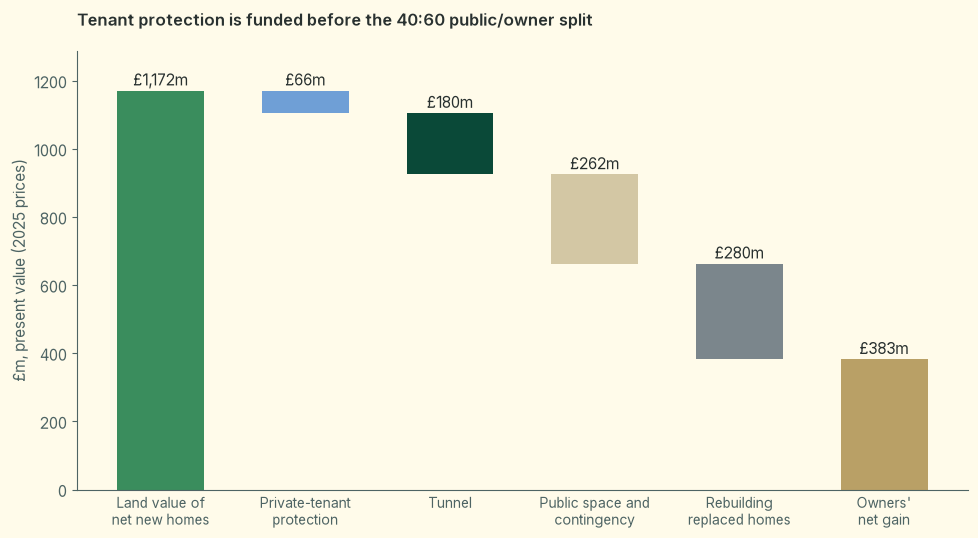

In [ ]:
fig, ax = plt.subplots(figsize=(11.5, 5.7))
steps = [
    ("Land value of\nnet new homes", 0, pv["land"], COLOURS["green"]),
    ("Private-tenant\nprotection", pv["distributable"], pv["tenant_support"], COLOURS["housing"]),
    ("Tunnel", pv["distributable"] - tunnel, tunnel, COLOURS["tunnel"]),
    ("Public space and\ncontingency", pv["distributable"] - pv["reserve"], pv["reserve"] - tunnel, COLOURS["rest"]),
    ("Rebuilding\nreplaced homes", pv["owners"], pv["rebuild"], COLOURS["jubilee"]),
    ("Owners'\nnet gain", 0, pv["owners"], COLOURS["other"]),
]
for i, (name, bottom, height, colour) in enumerate(steps):
    ax.bar(i, height, bottom=bottom, color=colour, width=0.6)
    ax.text(i, bottom + height + 15, f"£{height:,.0f}m", ha="center", fontsize=11)
ax.set_xticks(range(len(steps)), [s[0] for s in steps], fontsize=10)
ax.tick_params(axis="x", length=0)
ax.set_ylabel(f"£m, present value ({PRICE_YEAR} prices)")
ax.set_title("Tenant protection is funded before the 40:60 public/owner split", pad=18)
ax.set_ylim(0, pv["land"] * 1.1)
fig.savefig(FIGURES / "value_split.png")

### How much readjustment pays for the tunnel

At 400 homes/ha, split each level's land value four ways: private-tenant protection, public funding,
rebuilding the homes that make way, and owners' net gain. The public share is 40% of value **after protection**;
the tunnel is covered once that share passes its cost. The household count and protection costs change with
the amount of land rebuilt and the length of build-out.

In [ ]:
def split_at(share, target=400, reserve=0.4, rate=RATES[RATE], package=TENANT_CENTRAL, private_share=PRIVATE_SHARE):
    "Present values (£m) of the land value split at one level of readjustment."
    values = appraise(share, target, reserve=reserve, r=rate, package=package, private_share=private_share)
    return {k: values[k] / 1e6 for k in MONEY_KEYS}

In [ ]:
test_close(split_at(0.35)["reserve"], h["reserve PV " + RATE])
levels = pd.DataFrame({x: split_at(x) for x in np.linspace(0, 0.6, 121)}).T
reserve_260 = pd.Series({x: split_at(x, target=260)["reserve"] for x in levels.index})


def break_even(shares, funding, cost):
    "Interpolate a monotone funding curve; return NaN if it never covers the cost."
    assert np.all(np.diff(funding) >= 0), "Funding must be monotone for interpolation"
    return float(np.interp(cost, funding, shares)) if max(funding) >= cost else np.nan


test_eq(np.isnan(break_even([0, 0.6], [0, 100], 180)), True)
breakeven = break_even(levels.index, levels.reserve, tunnel)
breakeven_260 = break_even(reserve_260.index, reserve_260, tunnel)
test_close(split_at(breakeven)["reserve"], tunnel, eps=0.05)
test_close(split_at(breakeven_260, target=260)["reserve"], tunnel, eps=0.05)
f"Public funding covers the tunnel from {breakeven:.1%} rebuilt at 400 homes/ha ({breakeven_260:.1%} at 260/ha), after protection"

'Public funding covers the tunnel from 12.5% rebuilt at 400 homes/ha (22.4% at 260/ha), after protection'

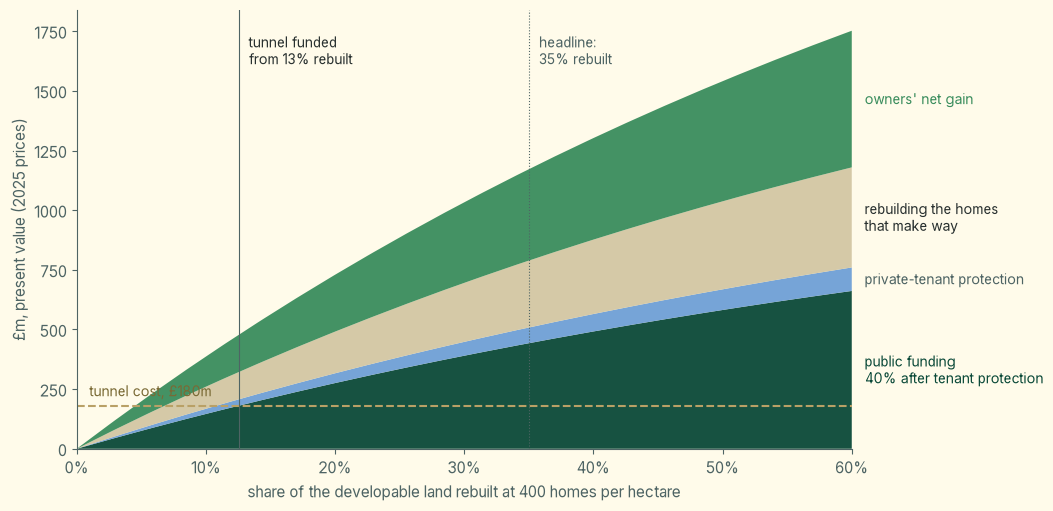

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.7))
x = levels.index * 100
ax.stackplot(
    x,
    levels.reserve,
    levels.tenant_support,
    levels.rebuild,
    levels.owners,
    colors=[COLOURS["ink"], COLOURS["housing"], COLOURS["rest"], COLOURS["green"]],
    alpha=0.95,
)
ax.axhline(tunnel, color=COLOURS["other"], lw=1.5, ls="--")
ax.axvline(breakeven * 100, color=COLOURS["text"], lw=0.8)
ax.axvline(35, color=COLOURS["text"], lw=0.8, ls=":")
label = {"fontsize": 10, "va": "center"}
right = x[-1]
edge = levels.iloc[-1]
ax.text(right + 1, edge.reserve / 2, "public funding\n40% after tenant protection", color=COLOURS["ink"], **label)
ax.text(right + 1, edge.reserve + edge.tenant_support / 2, "private-tenant protection", color=COLOURS["text"], **label)
ax.text(
    right + 1, edge.reserve + edge.tenant_support + edge.rebuild / 2, "rebuilding the homes\nthat make way", **label
)
ax.text(right + 1, edge.land - edge.owners / 2, "owners' net gain", color=COLOURS["green"], **label)
ax.text(1, tunnel + 40, f"tunnel cost, £{tunnel:.0f}m", color="#7A6A35", fontsize=10)
ax.text(breakeven * 100 + 0.8, levels.land.max() * 0.92, f"tunnel funded\nfrom {breakeven:.0%} rebuilt", fontsize=10)
ax.text(35.8, levels.land.max() * 0.92, "headline:\n35% rebuilt", fontsize=10, color=COLOURS["text"])
ax.set(xlim=(0, right), ylim=(0, None))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("share of the developable land rebuilt at 400 homes per hectare")
ax.set_ylabel(f"£m, present value ({PRICE_YEAR} prices)")
fig.savefig(FIGURES / "readjustment_levels.png")

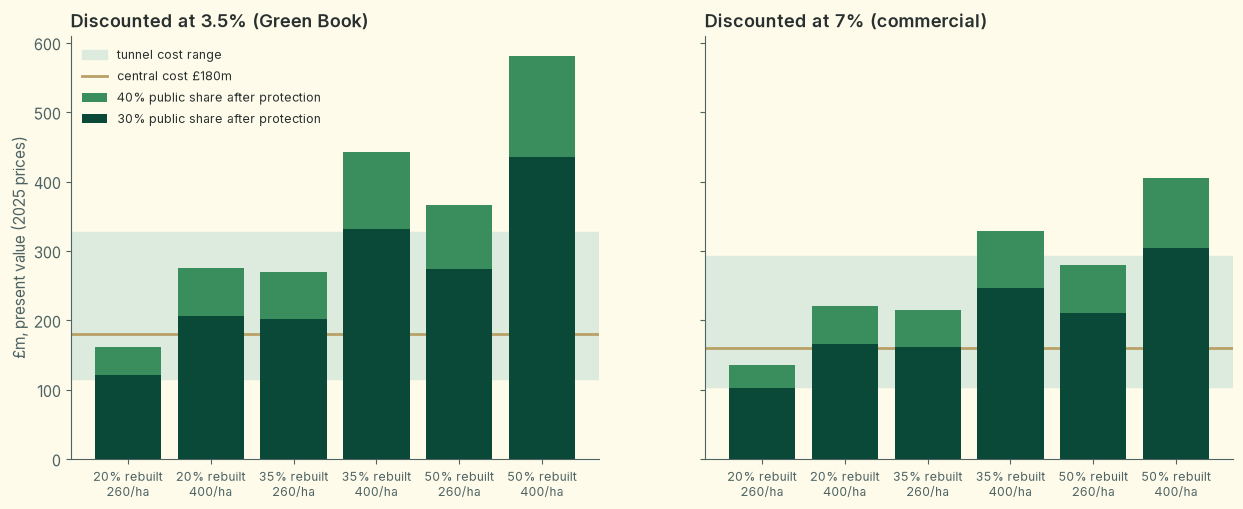

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
labelled = central.assign(label=[f"{s:.0%} rebuilt\n{t}/ha" for s, t in zip(central.share, central.target)])
for ax, rate in zip(axes, RATES):
    wide = labelled.pivot_table(index="label", columns="reserve_share", values=f"reserve PV {rate}", sort=False)
    c = pv_cost[rate]
    ax.axhspan(c["low"], c["high"], color=COLOURS["pale"], label="tunnel cost range")
    ax.axhline(c["central"], color=COLOURS["other"], lw=2, label=f"central cost £{c['central']:.0f}m")
    x = np.arange(len(wide))
    ax.bar(x, wide[0.4], color=COLOURS["green"], label="40% public share after protection", zorder=3)
    ax.bar(x, wide[0.3], color=COLOURS["ink"], label="30% public share after protection", zorder=3)
    ax.set_xticks(x, wide.index, fontsize=9)
    ax.set_title(f"Discounted at {rate}", fontsize=13)
axes[0].set_ylabel(f"£m, present value ({PRICE_YEAR} prices)")
axes[0].legend(loc="upper left", fontsize=9)
fig.savefig(FIGURES / "funding_vs_cost.png")